# Stage 01 — Infinite-width Gaussian-RBF advection–diffusion predictor

Python/Jupyter conversion of `STAGE_01_INF_RBF_ADV_DIFF_PAPER.m`.

The notebook preserves the original slab-wise infinite-width Gaussian-RBF
predictor, independent off-collocation residual probes, and low/mid/high
residual-attention map.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf
from pathlib import Path
from time import perf_counter

def radical_inverse(n, b):
    n = np.asarray(n, dtype=int).copy()
    r = np.zeros_like(n, dtype=float)
    f = 1.0 / b
    while np.any(n > 0):
        r += f * (n % b)
        n //= b
        f /= b
    return r

def halton_2d_prefix(N):
    idx = np.arange(1, N + 1)
    return radical_inverse(idx, 2), radical_inverse(idx, 3)

def dilate_nonperiodic(mask, radius):
    mask = np.asarray(mask, dtype=bool)
    out = np.zeros_like(mask)
    for j in np.flatnonzero(mask):
        j1 = max(0, j - radius)
        j2 = min(mask.size, j + radius + 1)
        out[j1:j2] = True
    return out

def attention_to_levels_nonperiodic(score, theta_mid, theta_high, high_radius, mid_radius):
    score = np.asarray(score, dtype=float).ravel()
    if np.max(score) <= np.finfo(float).eps:
        return np.ones(score.size, dtype=int)
    high_raw = score >= theta_high
    mid_raw = score >= theta_mid
    if not np.any(high_raw):
        high_raw[np.argmax(score)] = True
    high_mask = dilate_nonperiodic(high_raw, high_radius)
    mid_mask = dilate_nonperiodic(mid_raw | high_raw, mid_radius)
    levels = np.ones(score.size, dtype=int)
    levels[mid_mask] = 2
    levels[high_mask] = 3
    return levels

def rbf1d_uniform_derivs_full(x, y, sigma, ca, cb):
    x = np.asarray(x, dtype=float).reshape(-1, 1)
    y = np.asarray(y, dtype=float).reshape(1, -1)
    m = 0.5 * (x + y)
    d = x - y
    A = 0.5 * d
    za = ca - m
    zb = cb - m

    Ed = np.exp(-(d**2) / (4 * sigma**2))
    ea = np.exp(-(za / sigma)**2)
    eb = np.exp(-(zb / sigma)**2)
    E = erf(zb / sigma) - erf(za / sigma)

    J0 = 0.5 * sigma * np.sqrt(np.pi) * E
    J1 = 0.5 * sigma**2 * (ea - eb)
    J2 = 0.25 * sigma**3 * np.sqrt(np.pi) * E - 0.5 * sigma**2 * (zb * eb - za * ea)
    J3 = -0.5 * sigma**2 * (zb**2 * eb - za**2 * ea) + sigma**2 * J1
    J4 = -0.5 * sigma**2 * (zb**3 * eb - za**3 * ea) + 1.5 * sigma**2 * J2

    C = 1.0 / (cb - ca)
    F = C * Ed

    Iq = A * J0 - J1
    Ir = -A * J0 - J1
    Iq2 = A**2 * J0 - 2 * A * J1 + J2
    Ir2 = A**2 * J0 + 2 * A * J1 + J2
    Iqr = J2 - A**2 * J0
    Iq2r = -A**3 * J0 + A**2 * J1 + A * J2 - J3
    Iqr2 = A**3 * J0 + A**2 * J1 - A * J2 - J3
    Iq2r2 = A**4 * J0 - 2 * A**2 * J2 + J4

    K = F * J0
    K1 = -F * Iq / sigma**2
    K2 = -F * Ir / sigma**2
    K11 = F * (Iq2 / sigma**4 - J0 / sigma**2)
    K22 = F * (Ir2 / sigma**4 - J0 / sigma**2)
    K12 = F * Iqr / sigma**4
    K112 = F * (-Iq2r / sigma**6 + Ir / sigma**4)
    K122 = F * (-Iqr2 / sigma**6 + Iq / sigma**4)
    K1122 = F * (Iq2r2 / sigma**8 - (Iq2 + Ir2) / sigma**6 + J0 / sigma**4)
    return K, K1, K2, K11, K22, K12, K112, K122, K1122

def kernel_2d_advdiff(cfg, x1, t1, x2, t2, type1, type2):
    Kx, Kx1, Kx2, Kx11, Kx22, Kx12, Kx112, Kx122, Kx1122 = \
        rbf1d_uniform_derivs_full(x1, x2, cfg["sigma_x"], cfg["cx_a"], cfg["cx_b"])
    Kt, Kt1, Kt2, _, _, Kt12, _, _, _ = \
        rbf1d_uniform_derivs_full(t1, t2, cfg["sigma_t"], cfg["ct_a"], cfg["ct_b"])

    a = cfg["adv_speed"]
    nu = cfg["nu"]

    if type1 == "val" and type2 == "val":
        K = Kx * Kt
    elif type1 == "pde" and type2 == "val":
        K = Kx * Kt1 + a * Kx1 * Kt - nu * Kx11 * Kt
    elif type1 == "val" and type2 == "pde":
        K = Kx * Kt2 + a * Kx2 * Kt - nu * Kx22 * Kt
    elif type1 == "pde" and type2 == "pde":
        K = (
            Kx * Kt12
            + a * Kx2 * Kt1 - nu * Kx22 * Kt1
            + a * Kx1 * Kt2 + a**2 * Kx12 * Kt - a * nu * Kx122 * Kt
            - nu * Kx11 * Kt2 - a * nu * Kx112 * Kt + nu**2 * Kx1122 * Kt
        )
    else:
        raise ValueError("Unknown kernel functional type.")
    return K / cfg["norm_const"]

def compute_kernel_norm(cfg):
    xr = 0.5 * (cfg["XL"] + cfg["XR"])
    tr = 0.5 * cfg["dt"]
    Kx = rbf1d_uniform_derivs_full([xr], [xr], cfg["sigma_x"], cfg["cx_a"], cfg["cx_b"])[0]
    Kt = rbf1d_uniform_derivs_full([tr], [tr], cfg["sigma_t"], cfg["ct_a"], cfg["ct_b"])[0]
    return float((Kx * Kt)[0, 0])

def build_constraint_gram(cfg, tr):
    xP, tP = tr["xP"], tr["tP"]
    xB, tB = tr["xB"], tr["tB"]
    xI, tI = tr["xI"], tr["tI"]
    wP, wB, wI = tr["wP"], tr["wB"], tr["wI"]

    KPP = kernel_2d_advdiff(cfg, xP, tP, xP, tP, "pde", "pde")
    KPB = kernel_2d_advdiff(cfg, xP, tP, xB, tB, "pde", "val")
    KPI = kernel_2d_advdiff(cfg, xP, tP, xI, tI, "pde", "val")
    KBB = kernel_2d_advdiff(cfg, xB, tB, xB, tB, "val", "val")
    KBI = kernel_2d_advdiff(cfg, xB, tB, xI, tI, "val", "val")
    KII = kernel_2d_advdiff(cfg, xI, tI, xI, tI, "val", "val")

    K = np.block([
        [wP*wP*KPP,         wP*wB*KPB,         wP*wI*KPI],
        [wB*wP*KPB.T,       wB*wB*KBB,         wB*wI*KBI],
        [wI*wP*KPI.T,       wI*wB*KBI.T,       wI*wI*KII],
    ])
    return 0.5 * (K + K.T)

def predict_value(cfg, tr, coeff, xq, tq):
    NP = len(tr["xP"])
    NB = len(tr["xB"])
    aP = coeff[:NP]
    aB = coeff[NP:NP+NB]
    aI = coeff[NP+NB:]

    KP = kernel_2d_advdiff(cfg, xq, tq, tr["xP"], tr["tP"], "val", "pde")
    KB = kernel_2d_advdiff(cfg, xq, tq, tr["xB"], tr["tB"], "val", "val")
    KI = kernel_2d_advdiff(cfg, xq, tq, tr["xI"], tr["tI"], "val", "val")
    return (tr["wP"] * KP) @ aP + (tr["wB"] * KB) @ aB + (tr["wI"] * KI) @ aI

def predict_pde_residual(cfg, tr, coeff, xq, tq):
    NP = len(tr["xP"])
    NB = len(tr["xB"])
    aP = coeff[:NP]
    aB = coeff[NP:NP+NB]
    aI = coeff[NP+NB:]

    KP = kernel_2d_advdiff(cfg, xq, tq, tr["xP"], tr["tP"], "pde", "pde")
    KB = kernel_2d_advdiff(cfg, xq, tq, tr["xB"], tr["tB"], "pde", "val")
    KI = kernel_2d_advdiff(cfg, xq, tq, tr["xI"], tr["tI"], "pde", "val")
    return (tr["wP"] * KP) @ aP + (tr["wB"] * KB) @ aB + (tr["wI"] * KI) @ aI

In [3]:
# Problem
XL, XR = 0.0, 1.0
L = XR - XL
a = 0.5
nu = 0.001

nSlabs = 100
dt_slab = 0.01
Tfinal = nSlabs * dt_slab

def uexact(x, t):
    x = np.asarray(x, dtype=float)
    return (1.0 / np.sqrt(4*t + 1)) * np.exp(-((x - 0.2 - a*t)**2) / (nu * (4*t + 1)))

# Attention/collocation setup
NBx = 25
x_edges = np.linspace(XL, XR, NBx + 1)
Npde_per_block_pilot = 4
Nic = 401
Nbc_each = 11
probe_nx, probe_nt = 10, 7

attention_rms_weight = 0.70
attention_max_weight = 0.30
theta_high, theta_mid = 0.35, 0.10
high_buffer_radius_x, mid_buffer_radius_x = 1, 2

sigma_x, sigma_t = 0.020, 0.010
cx_a, cx_b = XL - 0.20*L, XR + 0.20*L
ct_a, ct_b = -1.5*dt_slab, 2.5*dt_slab
ridge_rel, eig_tol_rel = 1e-9, 1e-13

# Pilot PDE points
hx01, ht01 = halton_2d_prefix(Npde_per_block_pilot)
xP = np.zeros(NBx * Npde_per_block_pilot)
tP = np.zeros_like(xP)
kk = 0
for jx in range(NBx):
    xa, xb = x_edges[jx], x_edges[jx+1]
    ids = slice(kk, kk + Npde_per_block_pilot)
    xP[ids] = xa + (xb-xa)*hx01
    tP[ids] = dt_slab*ht01
    kk += Npde_per_block_pilot

xI = np.linspace(XL, XR, Nic)
tI = np.zeros(Nic)

tB_each = np.linspace(0, dt_slab, Nbc_each)
xB = np.r_[np.full(Nbc_each, XL), np.full(Nbc_each, XR)]
tB = np.r_[tB_each, tB_each]
Nbc = len(xB)

Npde = len(xP)
wP, wB, wI = 1/np.sqrt(Npde), 1/np.sqrt(Nbc), 1/np.sqrt(Nic)

kcfg = dict(
    sigma_x=sigma_x, sigma_t=sigma_t,
    cx_a=cx_a, cx_b=cx_b, ct_a=ct_a, ct_b=ct_b,
    XL=XL, XR=XR, dt=dt_slab, adv_speed=a, nu=nu
)
kcfg["norm_const"] = compute_kernel_norm(kcfg)

train = dict(xP=xP, tP=tP, xB=xB, tB=tB, xI=xI, tI=tI,
             wP=wP, wB=wB, wI=wI)

print("STAGE 01: INFINITE-RBF ADVECTION-DIFFUSION PREDICTOR")
print(f"a={a:.4f}, nu={nu:.4e}, blocks={NBx}, pilot PDE points={Npde}")
print(f"sigma_x={sigma_x:.5f}, sigma_t={sigma_t:.5f}")

STAGE 01: INFINITE-RBF ADVECTION-DIFFUSION PREDICTOR
a=0.5000, nu=1.0000e-03, blocks=25, pilot PDE points=100
sigma_x=0.02000, sigma_t=0.01000


In [4]:
# Precompute fixed predictor system/eigendecomposition
_t_stage1_total0 = perf_counter()

_t0 = perf_counter()
Ktrain = build_constraint_gram(kcfg, train)
t_stage1_assembly = perf_counter() - _t0

_t0 = perf_counter()
d, V = eigh(Ktrain)
dmax = np.max(d)
if dmax <= 0:
    raise RuntimeError("Predictor kernel Gram matrix is not positive on the retained scale.")

lam = ridge_rel * dmax
keep = d > eig_tol_rel * dmax
Vin = V[:, keep]
din = d[keep] + lam
t_stage1_factorization = perf_counter() - _t0

print(f"Predictor constraints: {Ktrain.shape[0]}")
print(f"Retained modes: {np.sum(keep)} / {len(d)}")
print(f"Ridge lambda: {lam:.3e}")
print(f"Kernel/operator assembly time = {t_stage1_assembly:.6f} s")
print(f"Spectral factorization time   = {t_stage1_factorization:.6f} s")


Predictor constraints: 523
Retained modes: 188 / 523
Ridge lambda: 3.161e-07
Kernel/operator assembly time = 0.061276 s
Spectral factorization time   = 0.046847 s


In [5]:
# Slab marching
uI = uexact(xI, 0.0)
Nx_plot = 801
x_plot = np.linspace(XL, XR, Nx_plot)
plot_times = np.arange(nSlabs + 1) * dt_slab
Uplot = np.zeros((nSlabs + 1, Nx_plot))
Uplot[0, :] = uexact(x_plot, 0.0)

Rmat = np.zeros((nSlabs, NBx))
Rmax_mat = np.zeros((nSlabs, NBx))
attention_score_mat = np.zeros((nSlabs, NBx))
Lmat = np.zeros((nSlabs, NBx), dtype=int)
coeff_all = np.zeros((Ktrain.shape[0], nSlabs))

t_stage1_coeff = 0.0
t_stage1_residual_probe = 0.0
t_stage1_prediction = 0.0

for s in range(nSlabs):
    TL = s * dt_slab

    yB = uexact(xB, TL + tB)
    rhs = np.r_[np.zeros(Npde), wB*yB, wI*uI]
    _t0 = perf_counter()
    coeff = Vin @ ((Vin.T @ rhs) / din)
    t_stage1_coeff += perf_counter() - _t0
    coeff_all[:, s] = coeff

    _t0 = perf_counter()
    Rrms = np.zeros(NBx)
    Rmx = np.zeros(NBx)
    for jx in range(NBx):
        xa, xb = x_edges[jx], x_edges[jx+1]
        xp = np.linspace(xa, xb, probe_nx + 2)[1:-1]
        tp = np.linspace(0, dt_slab, probe_nt + 2)[1:-1]
        XP, TP = np.meshgrid(xp, tp)
        rq = predict_pde_residual(kcfg, train, coeff, XP.ravel(), TP.ravel())
        Rrms[jx] = np.sqrt(np.mean(rq**2))
        Rmx[jx] = np.max(np.abs(rq))

    nr = Rrms / max(np.max(Rrms), np.finfo(float).eps)
    nm = Rmx / max(np.max(Rmx), np.finfo(float).eps)
    score = attention_rms_weight*nr + attention_max_weight*nm
    levels = attention_to_levels_nonperiodic(
        score, theta_mid, theta_high, high_buffer_radius_x, mid_buffer_radius_x
    )

    Rmat[s] = Rrms
    Rmax_mat[s] = Rmx
    attention_score_mat[s] = score
    Lmat[s] = levels
    t_stage1_residual_probe += perf_counter() - _t0

    _t0 = perf_counter()
    uq_top = predict_value(kcfg, train, coeff, x_plot, np.full_like(x_plot, dt_slab))
    Uplot[s+1, :] = uq_top
    uI = predict_value(kcfg, train, coeff, xI, np.full_like(xI, dt_slab))
    t_stage1_prediction += perf_counter() - _t0

    if (s+1) % 10 == 0 or s == 0:
        print(
            f"slab {s+1:3d} [{TL:6.3f},{TL+dt_slab:6.3f}] "
            f"maxRMS={np.max(Rrms):9.3e} "
            f"low/mid/high={np.sum(levels==1)}/{np.sum(levels==2)}/{np.sum(levels==3)}"
        )

u_ex_final = uexact(x_plot, Tfinal)
err_final = Uplot[-1] - u_ex_final
predictor_rmse = np.sqrt(np.mean(err_final**2))
predictor_max_error = np.max(np.abs(err_final))

print(f"Predictor final RMSE      = {predictor_rmse:.3e}")
print(f"Predictor final max error = {predictor_max_error:.3e}")
t_stage1_core = t_stage1_assembly + t_stage1_factorization + t_stage1_coeff
t_stage1_total = perf_counter() - _t_stage1_total0
print(f"Coefficient solves (all slabs) = {t_stage1_coeff:.6f} s")
print(f"Residual probing/adaptation    = {t_stage1_residual_probe:.6f} s")
print(f"Slab prediction/transfer       = {t_stage1_prediction:.6f} s")
print(f"Predictor core CFKS time       = {t_stage1_core:.6f} s")
print(f"Stage-1 total elapsed time     = {t_stage1_total:.6f} s")


slab   1 [ 0.000, 0.010] maxRMS=8.475e-01 low/mid/high=17/2/6
slab  10 [ 0.090, 0.100] maxRMS=6.792e-01 low/mid/high=16/5/4
slab  20 [ 0.190, 0.200] maxRMS=5.165e-01 low/mid/high=15/4/6
slab  30 [ 0.290, 0.300] maxRMS=3.688e-01 low/mid/high=15/4/6
slab  40 [ 0.390, 0.400] maxRMS=2.972e-01 low/mid/high=15/3/7
slab  50 [ 0.490, 0.500] maxRMS=2.899e-01 low/mid/high=14/4/7
slab  60 [ 0.590, 0.600] maxRMS=2.633e-01 low/mid/high=15/5/5
slab  70 [ 0.690, 0.700] maxRMS=2.282e-01 low/mid/high=15/5/5
slab  80 [ 0.790, 0.800] maxRMS=1.920e-01 low/mid/high=14/5/6
slab  90 [ 0.890, 0.900] maxRMS=1.842e-01 low/mid/high=14/5/6
slab 100 [ 0.990, 1.000] maxRMS=1.746e-01 low/mid/high=14/5/6
Predictor final RMSE      = 4.360e-02
Predictor final max error = 1.505e-01
Coefficient solves (all slabs) = 0.048230 s
Residual probing/adaptation    = 31.975909 s
Slab prediction/transfer       = 20.130436 s
Predictor core CFKS time       = 0.156353 s
Stage-1 total elapsed time     = 52.288007 s


In [6]:
# Save Python stage handoff
np.savez_compressed(
    "STAGE_01_INF_RBF_ADV_DIFF_attention_PAPER.npz",
    XL=XL, XR=XR, L=L, a=a, nu=nu, NBx=NBx, x_edges=x_edges,
    nSlabs=nSlabs, dt_slab=dt_slab, Tfinal=Tfinal,
    Npde_per_block_pilot=Npde_per_block_pilot, Npde=Npde,
    Nic=Nic, Nbc_each=Nbc_each, Nbc=Nbc,
    xP=xP, tP=tP, xI=xI, tI=tI, xB=xB, tB=tB, tB_each=tB_each,
    probe_nx=probe_nx, probe_nt=probe_nt,
    sigma_x=sigma_x, sigma_t=sigma_t, cx_a=cx_a, cx_b=cx_b, ct_a=ct_a, ct_b=ct_b,
    ridge_rel=ridge_rel, eig_tol_rel=eig_tol_rel, lam=lam, keep=keep,
    theta_high=theta_high, theta_mid=theta_mid,
    high_buffer_radius_x=high_buffer_radius_x, mid_buffer_radius_x=mid_buffer_radius_x,
    attention_rms_weight=attention_rms_weight, attention_max_weight=attention_max_weight,
    Rmat=Rmat, Rmax_mat=Rmax_mat, attention_score_mat=attention_score_mat, Lmat=Lmat,
    coeff_all=coeff_all, x_plot=x_plot, plot_times=plot_times, Uplot=Uplot,
    predictor_rmse=predictor_rmse, predictor_max_error=predictor_max_error,
    t_stage1_assembly=t_stage1_assembly,
    t_stage1_factorization=t_stage1_factorization,
    t_stage1_coeff=t_stage1_coeff,
    t_stage1_residual_probe=t_stage1_residual_probe,
    t_stage1_prediction=t_stage1_prediction,
    t_stage1_core=t_stage1_core,
    t_stage1_total=t_stage1_total,
    u_ex_final=u_ex_final, err_final=err_final
)
print("Saved STAGE_01_INF_RBF_ADV_DIFF_attention_PAPER.npz")

Saved STAGE_01_INF_RBF_ADV_DIFF_attention_PAPER.npz


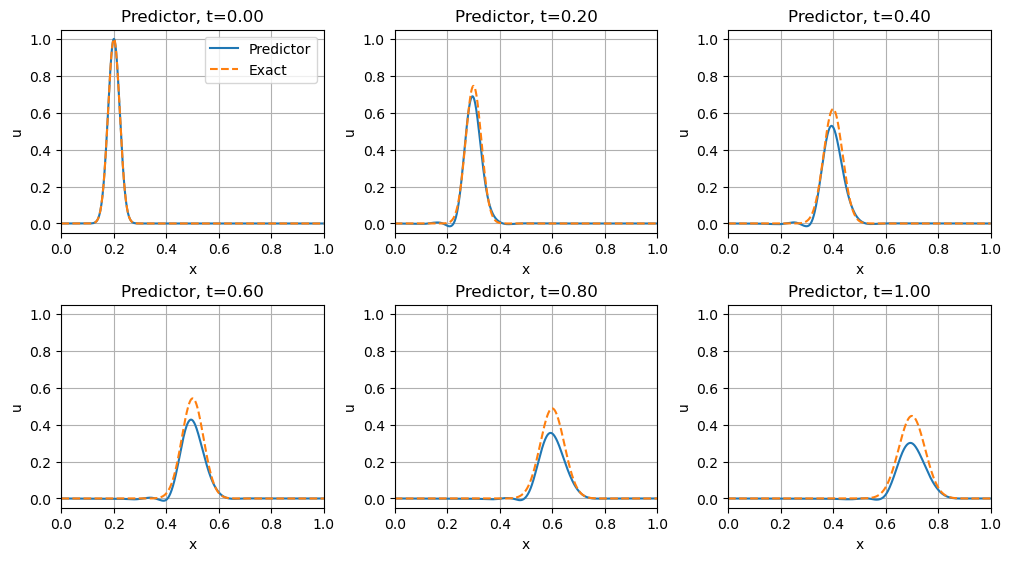

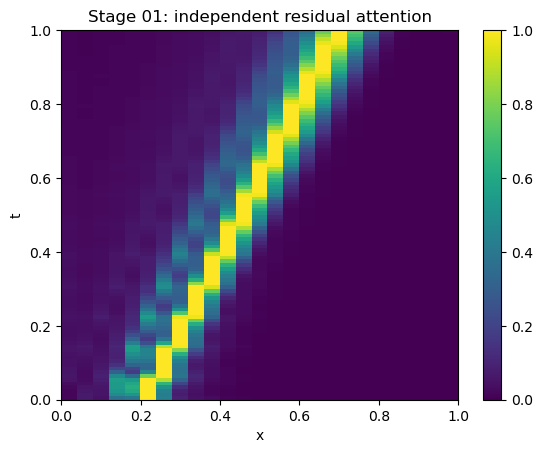

In [7]:
# Diagnostic plots
fig_times = [0, .2, .4, .6, .8, 1.0]
fig, axes = plt.subplots(2, 3, figsize=(10, 5.5), constrained_layout=True)
for ax, tq in zip(axes.flat, fig_times):
    ir = np.argmin(np.abs(plot_times - tq))
    ax.plot(x_plot, Uplot[ir], label="Predictor")
    ax.plot(x_plot, uexact(x_plot, plot_times[ir]), "--", label="Exact")
    ax.set(xlim=(XL, XR), ylim=(-0.05, 1.05), xlabel="x", ylabel="u",
           title=f"Predictor, t={plot_times[ir]:.2f}")
    ax.grid(True)
axes.flat[0].legend()
plt.show()

x_cent = 0.5*(x_edges[:-1] + x_edges[1:])
t_cent = (np.arange(nSlabs) + 0.5)*dt_slab

fig, ax = plt.subplots()
im = ax.imshow(attention_score_mat, origin="lower", aspect="auto",
               extent=[x_edges[0], x_edges[-1], 0, Tfinal], vmin=0, vmax=1)
fig.colorbar(im, ax=ax)
ax.set(xlabel="x", ylabel="t", title="Stage 01: independent residual attention")
plt.show()